# 01 — Correção dos setores com várias partes

## O que foi autorizado?

Em 04/11/2026, a autora autorizou:

1. Unir os polígonos de cada código de setor, contar a população e a **área oficial** uma vez e recalcular a distância a partir de um ponto representativo do conjunto.
2. Para unidades ligadas ao mesmo nó da rede, usar a **alternativa A: área de atendimento compartilhada**, preservando a contagem das unidades. A densidade na L2 será $D=m/A$, sendo $m$ o número de estabelecimentos do grupo.
3. Salvar os resultados corrigidos em uma pasta separada dos originais.

**Este notebook faz a correção e suas conferências.** A regressão L2 fica no notebook seguinte. A conferência que motivou estas decisões está em [00_conferencia_dados.ipynb](00_conferencia_dados.ipynb).

Não se conhece a população de cada parte geométrica. Por isso a correção mantém o setor como uma unidade e preserva a aproximação de um ponto representativo por setor. A união não preenche o espaço entre partes separadas.


In [1]:
from pathlib import Path
import hashlib
import gc
import sys
import unicodedata

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import osmnx as ox
import pandas as pd
from IPython.display import display, Markdown
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import dijkstra

RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "PLANO.md").exists())
PROC = RAIZ / "dados" / "processados"
ENTRADA = PROC / "distancias"
SAIDA = PROC / "corrigidos"
DIST_CORR = SAIDA / "distancias"
DIST_CORR.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(RAIZ / "scripts"))
import estilo  # Apenas cores e fontes.
estilo.aplicar()
LIGACAO_MAX_M = 2000

def slug(nome):
    return unicodedata.normalize("NFKD", nome).encode("ascii", "ignore").decode().split(" - ")[0].lower().replace(" ", "_")

capitais = pd.read_csv(PROC / "capitais_resumo.csv", dtype={"co_ibge7": str})
pa = pd.read_csv(PROC / "pa_capitais_corrigido.csv", dtype={"CO_CNES": str})
atributos = pd.read_csv(PROC / "setores_capitais.csv", dtype={"CD_SETOR": str})
assert not atributos.CD_SETOR.duplicated().any()
capitais["slug"] = capitais.municipio.map(slug)
cap_por_slug = capitais.set_index("slug")

def ler_csv(arquivo):
    return pd.read_csv(arquivo, dtype={"CD_SETOR": str, "CO_CNES": str})

def validos(tabela):
    return (tabela.populacao > 0) & (tabela.ligacao_m <= LIGACAO_MAX_M) & np.isfinite(tabela.d_m)

def sha256(arquivo):
    h = hashlib.sha256()
    with arquivo.open("rb") as leitura:
        for bloco in iter(lambda: leitura.read(1024 * 1024), b""):
            h.update(bloco)
    return h.hexdigest()

arquivos_originais = sorted(ENTRADA.glob("*_drive*_setores.csv"))
assert len(arquivos_originais) == 52
entradas_manifesto = arquivos_originais + [
    PROC / "pa_capitais_corrigido.csv", PROC / "capitais_resumo.csv",
    PROC / "setores_capitais.csv"
]
manifesto = pd.DataFrame({
    "arquivo": [str(p.relative_to(RAIZ)) for p in entradas_manifesto],
    "sha256": [sha256(p) for p in entradas_manifesto],
})
print("Arquivos de distância:", len(arquivos_originais))
print("Saída separada:", SAIDA.relative_to(RAIZ))


Arquivos de distância: 52
Saída separada: dados/processados/corrigidos


## 1. Localizar os setores com várias linhas

As versões SUS e todos usam a mesma geometria de setores, mas podem associar cada ponto a uma unidade diferente. Conferimos que ambas têm os mesmos códigos e números de partes.

Os atributos totais de população, área e renda devem ser constantes dentro de cada código. Caso não sejam, a execução para: a união por si só não resolveria esse conflito.


In [2]:
originais = {}
repetidos_por_capital = {}
resumo_entrada = []
for _, capital in capitais.loc[capitais.n_pa > 0].iterrows():
    chave = capital.slug
    tabelas = {}
    for versao, sufixo in [("SUS", "drive_sus"), ("Todos", "drive")]:
        tabela = ler_csv(ENTRADA / f"{chave}_{sufixo}_setores.csv")
        tabelas[versao] = tabela
        originais[(chave, versao)] = tabela
        repetidos = tabela.loc[tabela.CD_SETOR.duplicated(keep=False)]
        constantes = repetidos.groupby("CD_SETOR")[[
            "populacao", "AREA_KM2", "densidade", "renda_media", "favela"
        ]].nunique(dropna=False)
        assert (constantes <= 1).all().all(), f"Atributos conflitantes: {capital.municipio}"
    assert tabelas["SUS"].CD_SETOR.value_counts().equals(tabelas["Todos"].CD_SETOR.value_counts())
    codigos = set(tabelas["SUS"].loc[tabelas["SUS"].CD_SETOR.duplicated(keep=False), "CD_SETOR"])
    repetidos_por_capital[chave] = codigos
    resumo_entrada.append({
        "capital": capital.municipio,
        "linhas": len(tabelas["SUS"]),
        "setores_distintos": tabelas["SUS"].CD_SETOR.nunique(),
        "setores_com_varias_partes": len(codigos)
    })
resumo_entrada = pd.DataFrame(resumo_entrada)
display(resumo_entrada)
print("Setores a unir:", int(resumo_entrada.setores_com_varias_partes.sum()))
print("Capitais com correção geométrica:", int((resumo_entrada.setores_com_varias_partes > 0).sum()))


,capital,linhas,setores_distintos,setores_com_varias_partes
0,São Paulo - SP,27291,27291,0
1,Rio de Janeiro - RJ,13897,13777,28
2,Brasília - DF,5414,5414,0
3,Fortaleza - CE,4407,4407,0
4,Salvador - BA,4544,4541,2
5,Belo Horizonte - MG,5167,5166,1
6,Manaus - AM,3318,3280,2
7,Curitiba - PR,3190,3190,0
8,Recife - PE,2835,2834,1
9,Goiânia - GO,2310,2310,0


Setores a unir: 63
Capitais com correção geométrica: 13


## 2. Dijkstra na rede dirigida: o que será mantido?

Usamos as redes **drive já baixadas**, com a mesma maior componente fortemente conexa, projeção UTM, comprimentos e sentidos usados antes. Não há consultas à internet.

Invertemos as arestas e executamos Dijkstra a partir de todos os nós de atendimento. Assim obtemos a distância **do setor até o atendimento**, respeitando mãos de direção. Quando há arestas paralelas, usamos a menor distância entre o mesmo par de nós.

**Apenas os setores com várias partes têm seu ponto e sua associação recalculados.** Para os demais, conservamos os resultados anteriores e conferimos que não mudaram.

A escolha da fonte segue a regra anterior: se unidades se ligam ao mesmo nó, a primeira no cadastro representa o nó para a rota e para a distância de ligação ao estabelecimento. Agora **todas as unidades desse nó ficam registradas no grupo** para contar sua oferta na L2. Essa representação não distingue as entradas reais dos estabelecimentos.


In [3]:
def matriz_invertida(grafo):
    nos = list(grafo.nodes)
    indice = {no: i for i, no in enumerate(nos)}
    arestas = pd.DataFrame(
        [(indice[v], indice[u], dados["length"]) for u, v, dados in grafo.edges(data=True)],
        columns=["origem", "destino", "comprimento"]
    )
    arestas = arestas.groupby(["origem", "destino"], as_index=False).comprimento.min()
    arestas["comprimento"] = arestas.comprimento.clip(lower=0.01)
    matriz = coo_matrix(
        (arestas.comprimento, (arestas.origem, arestas.destino)),
        shape=(len(nos), len(nos))
    ).tocsr()
    return matriz, indice

def ligar_unidades(grafo, capital, versao, crs):
    cadastro = pa.loc[(pa.municipio == capital) & (pa.atende_sus | (versao == "Todos"))].copy()
    cadastro = gpd.GeoDataFrame(
        cadastro, geometry=gpd.points_from_xy(cadastro.lon, cadastro.lat), crs=4326
    ).to_crs(crs).reset_index(drop=True)
    cadastro["no"], cadastro["ligacao_m"] = ox.distance.nearest_nodes(
        grafo, cadastro.geometry.x, cadastro.geometry.y, return_dist=True
    )
    fontes = cadastro.drop_duplicates("no").copy()
    grupos = []
    for _, fonte in fontes.iterrows():
        membros = cadastro.loc[cadastro.no == fonte.no]
        grupos.append({
            "versao": versao, "capital": capital,
            "CO_CNES_representante": fonte.CO_CNES,
            "n_unidades": len(membros),
            "codigos_unidades": ";".join(membros.CO_CNES),
            "nomes_unidades": " | ".join(membros.NO_FANTASIA),
            "no": str(int(fonte.no))
        })
    return cadastro, fontes, grupos

def recalcular_setores(unidos, grafo, matriz, indice, fontes):
    pontos = unidos.geometry.representative_point()
    nos_setores, ligacoes = ox.distance.nearest_nodes(
        grafo, pontos.x, pontos.y, return_dist=True
    )
    distancias, _, origem = dijkstra(
        matriz, directed=True, indices=[indice[no] for no in fontes.no],
        min_only=True, return_predecessors=True
    )
    fonte_por_indice = {indice[fonte.no]: i for i, fonte in fontes.iterrows()}
    indices_setores = np.array([indice[no] for no in nos_setores])
    indices_fontes = [fonte_por_indice.get(int(no)) for no in origem[indices_setores]]
    assert all(i is not None for i in indices_fontes), "Setor sem fonte alcançável: investigar."
    escolhidas = fontes.loc[indices_fontes].reset_index(drop=True)
    resultado = pd.DataFrame({
        "CD_SETOR": unidos.CD_SETOR.to_numpy(),
        "CO_CNES": escolhidas.CO_CNES.to_numpy(),
        "dist_rede_m": distancias[indices_setores],
        "ligacao_m": ligacoes,
    })
    resultado["d_m"] = resultado.dist_rede_m + resultado.ligacao_m + escolhidas.ligacao_m.to_numpy()
    resultado["euclid_m"] = np.array([
        ponto.distance(unidade) for ponto, unidade in zip(pontos, escolhidas.geometry)
    ])
    assert np.isfinite(resultado.d_m).all()
    assert (resultado.d_m >= resultado.euclid_m - 1).all(), "Rede menor que linha reta: investigar."
    return resultado

def grupos_sem_correcao(chave, versao):
    capital = cap_por_slug.loc[chave, "municipio"]
    cadastro = pa.loc[(pa.municipio == capital) & (pa.atende_sus | (versao == "Todos"))]
    # Se cada estabelecimento aparece nas associações anteriores, nenhum foi
    # eliminado por compartilhar nó: todos representam grupos de uma unidade.
    presentes = set(originais[(chave, versao)].CO_CNES.dropna())
    assert set(cadastro.CO_CNES) == presentes, f"Conferir os grupos de {capital}"
    return [{
        "versao": versao, "capital": capital,
        "CO_CNES_representante": unidade.CO_CNES, "n_unidades": 1,
        "codigos_unidades": unidade.CO_CNES, "nomes_unidades": unidade.NO_FANTASIA,
        "no": ""
    } for _, unidade in cadastro.iterrows()]


## 3. Unir as partes, recalcular e salvar cópias corrigidas

Para cada código repetido:

1. Conferimos a área oficial e os atributos repetidos.
2. Unimos **todos** os polígonos do setor.
3. Obtemos um ponto dentro da geometria unida.
4. Calculamos sua associação e distância na rede.
5. Substituímos as várias linhas por uma, preservando os atributos totais uma única vez.

A área geométrica não substitui a área oficial do IBGE. Mantemos também setores sem moradores no arquivo completo; o filtro da análise será aplicado depois. As colunas `n_partes_original` e `geometria_unida` permitem identificar os setores alterados.


In [4]:
corrigidos = {}
registros_grupos = []
auditoria_capitais = []
auditoria_setores = []
for _, capital in capitais.loc[capitais.n_pa > 0].iterrows():
    chave, nome = capital.slug, capital.municipio
    codigos = repetidos_por_capital[chave]
    grafo = matriz = indice = unidos = None
    if codigos:
        malha = gpd.read_file(
            RAIZ / "dados" / "ibge" / "setores_gpkg" / f"{nome.split(' - ')[1]}_setores_CD2022.gpkg",
            where=f"CD_MUN='{capital.co_ibge7}'", columns=["CD_SETOR", "CD_SIT", "AREA_KM2"]
        )
        malha = malha.loc[malha.CD_SIT != "9"].to_crs(4674)
        crs_m = malha.estimate_utm_crs()  # Mesma definição do processamento anterior.
        partes = malha.loc[malha.CD_SETOR.isin(codigos)].to_crs(crs_m)
        assert set(partes.CD_SETOR) == codigos
        assert (partes.groupby("CD_SETOR").AREA_KM2.nunique(dropna=False) == 1).all()
        assert partes.geometry.is_valid.all(), "Geometria inválida: discutir antes de reparar."
        unidos = partes[["CD_SETOR", "geometry"]].dissolve(by="CD_SETOR", as_index=False)
        assert len(unidos) == len(codigos)
        assert unidos.geometry.is_valid.all()
        # Área oficial da malha e dos CSVs deve concordar.
        area_malha = partes.groupby("CD_SETOR").AREA_KM2.first().sort_index()
        area_csv = originais[(chave, "SUS")].loc[lambda d: d.CD_SETOR.isin(codigos)].groupby("CD_SETOR").AREA_KM2.first().sort_index()
        np.testing.assert_allclose(area_malha, area_csv, rtol=1e-9)

        grafo = ox.load_graphml(RAIZ / "dados" / "osm" / f"{chave}_drive.graphml")
        grafo = ox.truncate.largest_component(grafo, strongly=True)
        grafo = ox.project_graph(grafo, to_crs=crs_m)
        matriz, indice = matriz_invertida(grafo)

    for versao, sufixo in [("SUS", "drive_sus"), ("Todos", "drive")]:
        antigo = originais[(chave, versao)]
        colunas_originais = list(antigo.columns)
        if codigos:
            _, fontes, grupos = ligar_unidades(grafo, nome, versao, crs_m)
            registros_grupos.extend(grupos)
            novas_rotas = recalcular_setores(unidos, grafo, matriz, indice, fontes)
            # A seleção de uma linha só recupera os atributos que já conferimos
            # como constantes. As distâncias vêm do novo ponto, não dessa linha.
            atributos_setores = antigo.loc[antigo.CD_SETOR.isin(codigos)].drop_duplicates("CD_SETOR")[
                ["CD_SETOR", "populacao", "AREA_KM2", "densidade", "renda_media", "favela"]
            ]
            novos = atributos_setores.merge(novas_rotas, on="CD_SETOR", validate="one_to_one")
            novo = pd.concat([antigo.loc[~antigo.CD_SETOR.isin(codigos)], novos[colunas_originais]], ignore_index=True)
        else:
            novo = antigo.copy()
            registros_grupos.extend(grupos_sem_correcao(chave, versao))

        assert not novo.CD_SETOR.duplicated().any()
        assert set(novo.CD_SETOR) == set(antigo.CD_SETOR)
        pd.testing.assert_frame_equal(
            novo.loc[~novo.CD_SETOR.isin(codigos), colunas_originais].sort_values("CD_SETOR").reset_index(drop=True),
            antigo.loc[~antigo.CD_SETOR.isin(codigos), colunas_originais].sort_values("CD_SETOR").reset_index(drop=True)
        )
        totais_unicos = antigo.drop_duplicates("CD_SETOR")
        np.testing.assert_allclose(novo.populacao.sum(), totais_unicos.populacao.sum())
        np.testing.assert_allclose(novo.AREA_KM2.sum(), totais_unicos.AREA_KM2.sum())

        contagem_partes = antigo.CD_SETOR.value_counts()
        novo["n_partes_original"] = novo.CD_SETOR.map(contagem_partes).astype(int)
        novo["geometria_unida"] = novo.CD_SETOR.isin(codigos)
        novo = novo.sort_values("CD_SETOR").reset_index(drop=True)
        novo.to_csv(DIST_CORR / f"{chave}_{sufixo}_setores.csv", index=False)
        corrigidos[(chave, versao)] = novo

        antes, depois = antigo.loc[validos(antigo)], novo.loc[validos(novo)]
        auditoria_capitais.append({
            "capital": nome, "versao": versao, "setores_unidos": len(codigos),
            "linhas_antes": len(antigo), "linhas_depois": len(novo),
            "pop_total_linhas_antes": antigo.populacao.sum(), "pop_total_depois": novo.populacao.sum(),
            "linhas_validas_antes": len(antes), "setores_validos_depois": len(depois),
            "pop_valida_antes": antes.populacao.sum(), "pop_valida_depois": depois.populacao.sum(),
            "area_valida_antes_km2": antes.AREA_KM2.sum(), "area_valida_depois_km2": depois.AREA_KM2.sum(),
            "dist_media_antes_km": np.average(antes.d_m, weights=antes.populacao) / 1000,
            "dist_media_depois_km": np.average(depois.d_m, weights=depois.populacao) / 1000,
        })
        for codigo in sorted(codigos):
            linhas_antes = antigo.loc[antigo.CD_SETOR == codigo]
            linha_depois = novo.loc[novo.CD_SETOR == codigo].iloc[0]
            auditoria_setores.append({
                "capital": nome, "versao": versao, "CD_SETOR": codigo,
                "n_partes_original": len(linhas_antes), "populacao": linha_depois.populacao,
                "AREA_KM2": linha_depois.AREA_KM2,
                "pa_antes": ";".join(sorted(linhas_antes.CO_CNES.unique())),
                "pa_depois": linha_depois.CO_CNES,
                "d_min_antes_m": linhas_antes.d_m.min(), "d_max_antes_m": linhas_antes.d_m.max(),
                "d_depois_m": linha_depois.d_m, "ligacao_depois_m": linha_depois.ligacao_m,
                "n_linhas_validas_antes": int(validos(linhas_antes).sum()),
                "valido_depois": bool(validos(novo.loc[novo.CD_SETOR == codigo]).iloc[0]),
            })
    print(f"{nome}: {len(codigos)} setores unidos; versões SUS e todos salvas.", flush=True)
    del grafo, matriz, indice, unidos
    gc.collect()

grupos = pd.DataFrame(registros_grupos)
auditoria_capitais = pd.DataFrame(auditoria_capitais)
auditoria_setores = pd.DataFrame(auditoria_setores)
grupos.to_csv(SAIDA / "grupos_unidades.csv", index=False)
auditoria_capitais.to_csv(SAIDA / "auditoria_capitais.csv", index=False)
auditoria_setores.to_csv(SAIDA / "auditoria_setores_unidos.csv", index=False)
display(grupos.loc[grupos.n_unidades > 1])


São Paulo - SP: 0 setores unidos; versões SUS e todos salvas.


Rio de Janeiro - RJ: 28 setores unidos; versões SUS e todos salvas.


Brasília - DF: 0 setores unidos; versões SUS e todos salvas.


Fortaleza - CE: 0 setores unidos; versões SUS e todos salvas.


Salvador - BA: 2 setores unidos; versões SUS e todos salvas.


Belo Horizonte - MG: 1 setores unidos; versões SUS e todos salvas.


... (17 outputs left out)

Rio Branco - AC: 0 setores unidos; versões SUS e todos salvas.


Vitória - ES: 6 setores unidos; versões SUS e todos salvas.


Palmas - TO: 1 setores unidos; versões SUS e todos salvas.


,versao,capital,CO_CNES_representante,n_unidades,codigos_unidades,nomes_unidades,no
373,Todos,Porto Alegre - RS,4758749,2,4758749;6537650,PRONTO ATENDIMENTO DE CAMPANHA BOM JESUS | PRO...,445820977


## 4. Conferências: totais, códigos e preservação dos originais

Antes do filtro, a população corrigida deve coincidir com a soma de **uma ocorrência por código**, e a área oficial também. Isso confere os totais sem inventar moradores ou redistribuí-los entre partes.

Depois do filtro, alguns setores podem mudar de condição porque o ponto representativo e sua distância de ligação mudaram. A diferença após o filtro não é somente a remoção da repetição; mostramos ambos os efeitos.

No grupo compartilhado, os códigos dos dois estabelecimentos ficam registrados. A população e a área entram uma vez; o número de estabelecimentos entra na coluna `n_unidades`.


In [5]:
totais = []
for versao in ["SUS", "Todos"]:
    antes = pd.concat([d for (chave, v), d in originais.items() if v == versao], ignore_index=True)
    depois = pd.concat([d for (chave, v), d in corrigidos.items() if v == versao], ignore_index=True)
    assert not depois.CD_SETOR.duplicated().any()
    np.testing.assert_allclose(depois.loc[depois.populacao > 0].populacao.sum(),
                               antes.drop_duplicates("CD_SETOR").loc[lambda d: d.populacao > 0].populacao.sum())
    cadastro = pa.loc[pa.atende_sus] if versao == "SUS" else pa
    grupos_versao = grupos.loc[grupos.versao == versao]
    codigos_grupos = [codigo for membros in grupos_versao.codigos_unidades for codigo in membros.split(";")]
    assert len(codigos_grupos) == len(set(codigos_grupos))
    assert set(codigos_grupos) == set(cadastro.CO_CNES)
    assert grupos_versao.n_unidades.sum() == len(cadastro)
    antes_validos, depois_validos = antes.loc[validos(antes)], depois.loc[validos(depois)]
    totais.append({
        "versao": versao, "linhas_antes": len(antes), "setores_depois": len(depois),
        "pop_total_antes": antes.populacao.sum(), "pop_total_depois": depois.populacao.sum(),
        "linhas_validas_antes": len(antes_validos), "setores_validos_depois": len(depois_validos),
        "pop_valida_antes": antes_validos.populacao.sum(), "pop_valida_depois": depois_validos.populacao.sum(),
        "area_valida_antes_km2": antes_validos.AREA_KM2.sum(),
        "area_valida_depois_km2": depois_validos.AREA_KM2.sum(),
        "grupos_cadastrados": len(grupos_versao),
        "estabelecimentos_representados": grupos_versao.n_unidades.sum(),
    })
totais = pd.DataFrame(totais)
display(totais.set_index("versao").T)
totais.to_csv(SAIDA / "resumo_correcao.csv", index=False)

manifesto["sha256_apos"] = [sha256(RAIZ / nome) for nome in manifesto.arquivo]
assert (manifesto.sha256 == manifesto.sha256_apos).all(), "Arquivo original foi alterado."
manifesto.to_csv(SAIDA / "manifesto_entradas.csv", index=False)
print("Originais preservados: hashes conferem para", len(manifesto), "arquivos.")
print("Arquivos corrigidos de distância:", len(list(DIST_CORR.glob("*_setores.csv"))))


versao,SUS,Todos
linhas_antes,9.301900e+04,9.301900e+04
setores_depois,9.278200e+04,9.278200e+04
pop_total_antes,4.593250e+07,4.593250e+07
pop_total_depois,4.588307e+07,4.588307e+07
linhas_validas_antes,9.104300e+04,9.104300e+04
setores_validos_depois,9.098500e+04,9.098500e+04
pop_valida_antes,4.579838e+07,4.579838e+07
pop_valida_depois,4.577005e+07,4.577005e+07
area_valida_antes_km2,3.516692e+04,3.516692e+04
area_valida_depois_km2,3.399459e+04,3.399459e+04


Originais preservados: hashes conferem para 55 arquivos.
Arquivos corrigidos de distância: 52


## 5. Gráficos: o que mudou na população, na área e nas distâncias?

Os gráficos usam a versão **SUS**, principal. As versões compartilham a correção geométrica, mas a unidade mais próxima e a distância podem ser diferentes.

As barras mostram a diferença entre o total que entraria na análise antes e depois da correção. A figura seguinte compara as distâncias médias por capital. A linha diagonal representa ausência de mudança.

Não interpretamos uma mudança de distância causada por esta correção como melhoria ou piora real do atendimento: estamos corrigindo a medição, não mudando os serviços.


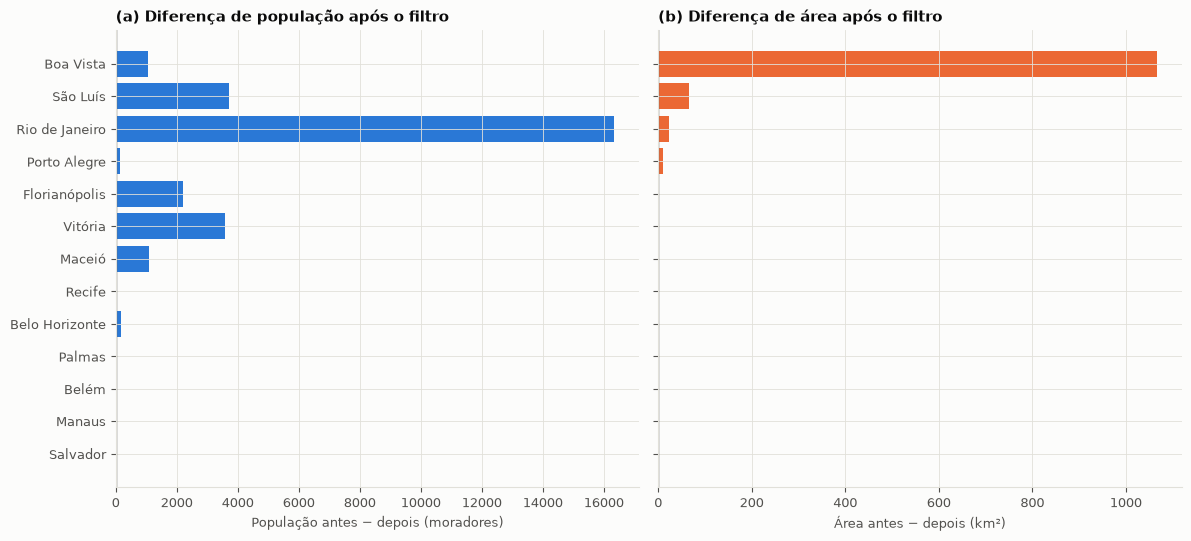

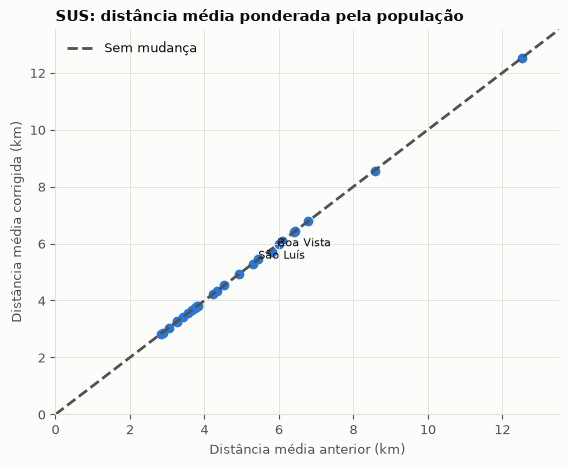

,capital,setores_unidos,pop_valida_antes,pop_valida_depois,area_valida_antes_km2,area_valida_depois_km2,dist_media_antes_km,dist_media_depois_km
2,Rio de Janeiro - RJ,28,6224073,6207737,923.304,899.283,3.821,3.818
8,Salvador - BA,2,2411113,2411113,253.513,253.513,2.828,2.828
10,Belo Horizonte - MG,1,2315731,2315560,317.595,317.589,3.421,3.421
12,Manaus - AM,2,2056753,2056753,1853.022,1853.022,4.231,4.231
16,Recife - PE,1,1488924,1488920,206.998,205.821,3.675,3.675
20,Porto Alegre - RS,3,1332995,1332845,472.287,461.445,4.920,4.918
22,Belém - PA,5,1259378,1259378,233.728,233.728,3.748,3.748
24,São Luís - MA,2,1041195,1037483,561.219,496.221,5.299,5.273
26,Maceió - AL,1,959023,957916,490.071,488.420,3.054,3.051
38,Florianópolis - SC,6,539405,537211,374.687,372.629,8.570,8.553


In [6]:
comparacao = auditoria_capitais.loc[auditoria_capitais.versao == "SUS"].copy()
comparacao["nome_curto"] = comparacao.capital.str.split(" - ").str[0]
comparacao["excesso_pop_antes"] = comparacao.pop_valida_antes - comparacao.pop_valida_depois
comparacao["excesso_area_antes"] = comparacao.area_valida_antes_km2 - comparacao.area_valida_depois_km2
mudancas = comparacao.loc[comparacao.setores_unidos > 0].sort_values("excesso_area_antes")

fig, eixos = plt.subplots(1, 2, figsize=(12, 5.5), sharey=True)
eixos[0].barh(mudancas.nome_curto, mudancas.excesso_pop_antes, color=estilo.AZUL)
eixos[1].barh(mudancas.nome_curto, mudancas.excesso_area_antes, color=estilo.LARANJA)
eixos[0].set_xlabel("População antes − depois (moradores)")
eixos[1].set_xlabel("Área antes − depois (km²)")
eixos[0].set_title("(a) Diferença de população após o filtro")
eixos[1].set_title("(b) Diferença de área após o filtro")
for ax in eixos:
    ax.axvline(0, color=estilo.TEXTO_2, linewidth=1)
fig.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(6.5, 5))
ax.scatter(comparacao.dist_media_antes_km, comparacao.dist_media_depois_km, color=estilo.AZUL)
limites = [0, max(comparacao.dist_media_antes_km.max(), comparacao.dist_media_depois_km.max()) * 1.08]
ax.plot(limites, limites, "--", color=estilo.TEXTO_2, label="Sem mudança")
for _, linha in comparacao.iterrows():
    if abs(linha.dist_media_depois_km - linha.dist_media_antes_km) > 0.02:
        ax.annotate(linha.nome_curto, (linha.dist_media_antes_km, linha.dist_media_depois_km),
                    xytext=(4, 4), textcoords="offset points", fontsize=8)
ax.set(xlim=limites, ylim=limites,
       xlabel="Distância média anterior (km)", ylabel="Distância média corrigida (km)")
ax.set_title("SUS: distância média ponderada pela população")
ax.legend()
plt.show()

display(comparacao.loc[comparacao.setores_unidos > 0, [
    "capital", "setores_unidos", "pop_valida_antes", "pop_valida_depois",
    "area_valida_antes_km2", "area_valida_depois_km2",
    "dist_media_antes_km", "dist_media_depois_km"
]].round(3))


## 6. Ler um caso individual e seguir para L2

A tabela abaixo retoma o exemplo de Belo Horizonte discutido com a autora. Ele deve aparecer como uma observação, com 171 moradores e a área oficial uma única vez.

**Atenção ao restante do projeto:** as figuras e os resumos antigos foram calculados com os arquivos anteriores. Os notebooks seguintes devem usar os arquivos corrigidos e refazer os resultados de cada fase antes de tratá-los como definitivos.


In [7]:
exemplo_bh = corrigidos[("belo_horizonte", "SUS")].loc[lambda d: d.CD_SETOR == "310620005670833"]
display(exemplo_bh)
assert len(exemplo_bh) == 1 and exemplo_bh.populacao.iloc[0] == 171
display(auditoria_setores.loc[
    (auditoria_setores.CD_SETOR == "310620005670833") & (auditoria_setores.versao == "SUS")
])
display(Markdown(
    "**Conferências concluídas.** Os setores não têm códigos repetidos; os totais por setor "
    "foram preservados; a rede foi usada respeitando a direção das vias; "
    "todos os estabelecimentos estão registrados nos grupos; e os arquivos originais "
    "permanecem idênticos. A próxima etapa está em "
    "[02_L2_densidade.ipynb](02_L2_densidade.ipynb)."
))


,CD_SETOR,populacao,AREA_KM2,densidade,renda_media,favela,CO_CNES,d_m,dist_rede_m,ligacao_m,euclid_m,n_partes_original,geometria_unida
2752,310620005670833,171,0.005635,30345.399653,1871.53,True,23310,859.470367,747.941796,29.384727,646.288895,2,True


,capital,versao,CD_SETOR,n_partes_original,populacao,AREA_KM2,pa_antes,pa_depois,d_min_antes_m,d_max_antes_m,d_depois_m,ligacao_depois_m,n_linhas_validas_antes,valido_depois
60,Belo Horizonte - MG,SUS,310620005670833,2,171,0.005635,23310,23310,859.470367,892.758691,859.470367,29.384727,2,True


**Conferências concluídas.** Os setores não têm códigos repetidos; os totais por setor foram preservados; a rede foi usada respeitando a direção das vias; todos os estabelecimentos estão registrados nos grupos; e os arquivos originais permanecem idênticos. A próxima etapa está em [02_L2_densidade.ipynb](02_L2_densidade.ipynb).